# Perceptron binaire : comprendre la convergence

**Deux jeux de données 2D · 120 exemples d'entraînement et 30 de test par jeu · Implémentation NumPy**

Ce notebook prolonge notre perceptron multiclasse. Nous utilisons maintenant **un seul vecteur de poids** et des cibles **−1 / +1**.

Nous allons comparer deux situations :

| Jeu | Attribution des classes | Séparable par une droite ? |
|---|---|---|
| A — Séparable | Gauche : −1 ; droite : +1 | Oui, la droite $x_1=0$ suffit |
| B — XOR | Même signe pour $x_1,x_2$ : +1 ; signes opposés : −1 | Non |

Les coordonnées sont les mêmes dans les deux jeux ; seules les étiquettes changent. Cela isole l'effet de la géométrie des classes.

**Objectifs :** coder la règle de mise à jour, comprendre les époques, distinguer les corrections en cours d'époque des erreurs finales, évaluer sur un test séparé et visualiser les frontières.

**Utilisation :** ouvrir dans Jupyter ou VS Code, puis exécuter les cellules dans l'ordre. Les données sont synthétiques et générées sur place : aucun téléchargement ni fichier externe n'est nécessaire. Les sorties sont déjà incluses.

## 1. Préparer les bibliothèques

Le modèle sera programmé à la main. Scikit-learn sert uniquement à séparer les indices d'entraînement et de test.

Si nécessaire, installer dans l'environnement Python du notebook : `numpy`, `matplotlib` et `scikit-learn`.

In [1]:
# Dans Jupyter, décommenter uniquement si les bibliothèques manquent :
# %pip install numpy matplotlib scikit-learn

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from sklearn.model_selection import train_test_split

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COULEURS = {-1: "#2463A5", 1: "#E58B27"}
CMAP = ListedColormap([COULEURS[-1], COULEURS[1]])
SEED_DONNEES = 42
SEED_ORDRE = 7

## 2. Construire les deux datasets

Nous créons quatre petits nuages autour de $(-2,-2)$, $(-2,2)$, $(2,-2)$ et $(2,2)$. Une perturbation uniforme **bornée entre −0,65 et +0,65** garde chaque nuage dans son quadrant. La séparabilité du jeu A est donc garantie par construction.

Les quatre premières observations sont exactement les centres. Elles serviront aussi à démontrer que le jeu XOR est non séparable.

Pour chaque jeu : **150 observations, 2 caractéristiques, 75 exemples par classe**. Les caractéristiques ont ici des échelles similaires ; nous travaillons directement dans ces coordonnées.

In [2]:
rng = np.random.default_rng(SEED_DONNEES)

centres = np.array([
    [-2.0, -2.0],
    [-2.0,  2.0],
    [ 2.0, -2.0],
    [ 2.0,  2.0],
])

# Les 4 centres + 146 points autour d'eux = 150 observations.
effectifs_autour = [37, 36, 37, 36]
blocs = [centres.copy()]
groupes = [np.arange(4)]

for k, (centre, effectif) in enumerate(zip(centres, effectifs_autour)):
    bruit = rng.uniform(-0.65, 0.65, size=(effectif, 2))
    blocs.append(centre + bruit)
    groupes.append(np.full(effectif, k))

X = np.vstack(blocs)
quadrants = np.concatenate(groupes)

# Dataset A : un signe différent de x1 correspond à une classe différente.
y_separable = np.where(X[:, 0] > 0, 1, -1)

# Dataset B : la classe dépend du signe du PRODUIT x1*x2.
# On l'appelle ici XOR ; inverser les deux noms de classes ne change rien.
y_xor = np.where(X[:, 0] * X[:, 1] > 0, 1, -1)

print("Dimensions de X :", X.shape)
for nom, y in [("Séparable", y_separable), ("XOR", y_xor)]:
    print(f"{nom:10s} : {np.sum(y == -1)} exemples −1, {np.sum(y == 1)} exemples +1")

Dimensions de X : (150, 2)
Séparable  : 75 exemples −1, 75 exemples +1
XOR        : 75 exemples −1, 75 exemples +1


## 3. Séparer entraînement et test

Nous gardons **120 exemples pour apprendre** et **30 pour tester**, avec les mêmes indices pour les deux jeux.

Pour cette expérience pédagogique, nous réservons les quatre centres à l'entraînement. Le jeu XOR d'entraînement contient ainsi un contre-exemple exact à la séparabilité. Nous tirons ensuite les 116 autres exemples d'entraînement et les 30 exemples de test, en conservant la représentation des quadrants.

Cette construction sert à garantir les propriétés de l'exercice. Dans une étude réelle, on définirait un protocole de séparation adapté au problème, sans sélectionner des observations en fonction des résultats du modèle.

**Le test ne sera jamais transmis à la fonction d'entraînement.** Les hyperparamètres ci-dessous sont fixés avant de regarder ses résultats.

In [3]:
indices_centres = np.arange(4)
indices_autres = np.arange(4, len(X))

indices_train_autres, indices_test = train_test_split(
    indices_autres,
    train_size=116,
    test_size=30,
    stratify=quadrants[indices_autres],
    random_state=SEED_DONNEES,
)

indices_train = np.concatenate((indices_centres, indices_train_autres))
indices_train = np.random.default_rng(SEED_DONNEES).permutation(indices_train)

X_train = X[indices_train].copy()
X_test = X[indices_test].copy()

y_sep_train = y_separable[indices_train]
y_sep_test = y_separable[indices_test]
y_xor_train = y_xor[indices_train]
y_xor_test = y_xor[indices_test]

assert len(np.intersect1d(indices_train, indices_test)) == 0
assert len(indices_train) == 120 and len(indices_test) == 30

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
for nom, yt, yte in [
    ("Séparable", y_sep_train, y_sep_test),
    ("XOR", y_xor_train, y_xor_test),
]:
    print(f"{nom:10s} — train : {np.sum(yt == -1)} / {np.sum(yt == 1)} ; "
          f"test : {np.sum(yte == -1)} / {np.sum(yte == 1)} (−1 / +1)")

X_train : (120, 2) | X_test : (30, 2)
Séparable  — train : 60 / 60 ; test : 15 / 15 (−1 / +1)
XOR        — train : 60 / 60 ; test : 15 / 15 (−1 / +1)


## 4. Observer les données avant d'apprendre

Les **cercles** sont les exemples d'entraînement ; les **triangles** sont les exemples de test. Les couleurs donnent les vraies classes. La ligne pointillée du premier graphique est un séparateur connu par construction, pas encore appris par le modèle.

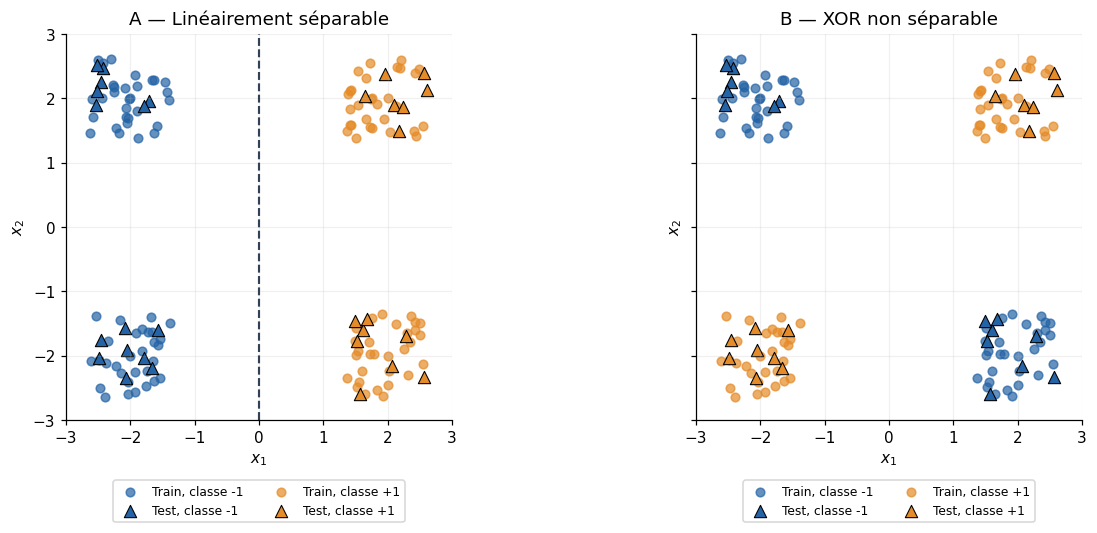

In [4]:
LIM = (-3.0, 3.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, nom, y in zip(axes, ["A — Linéairement séparable", "B — XOR non séparable"],
                     [y_separable, y_xor]):
    for classe in [-1, 1]:
        train = indices_train[y[indices_train] == classe]
        test = indices_test[y[indices_test] == classe]
        ax.scatter(X[train, 0], X[train, 1], color=COULEURS[classe],
                   s=32, alpha=0.7, label=f"Train, classe {classe:+d}")
        ax.scatter(X[test, 0], X[test, 1], color=COULEURS[classe],
                   marker="^", s=65, edgecolors="black", linewidths=0.7,
                   label=f"Test, classe {classe:+d}")
    ax.set(title=nom, xlabel="$x_1$", ylabel="$x_2$", xlim=LIM, ylim=LIM)
    ax.set_aspect("equal")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)

axes[0].axvline(0, linestyle="--", color="#334155", linewidth=1.4)
fig.tight_layout()
plt.show()

## 5. Pourquoi le XOR est-il impossible à séparer par une droite ?

Les deux centres positifs sont $(-2,-2)$ et $(2,2)$. Pour qu'ils aient tous deux un score strictement positif, il faudrait :

$$-2w_1-2w_2+b>0,\qquad 2w_1+2w_2+b>0.$$

En additionnant : $2b>0$.

Les deux centres négatifs sont $(-2,2)$ et $(2,-2)$. Pour qu'ils aient tous deux un score strictement négatif, il faudrait :

$$-2w_1+2w_2+b<0,\qquad 2w_1-2w_2+b<0.$$

En additionnant : $2b<0$. **Contradiction.** La convention « score nul → +1 » ne résout pas le problème : elle imposerait au mieux $b\geq 0$ pour les positifs, mais toujours $b<0$ pour les négatifs.

Les quatre centres étant dans le train, le problème est réellement non séparable, et pas simplement difficile à optimiser. Ajouter des époques ne peut pas rendre possible une droite qui n'existe pas.

## 6. Le perceptron binaire : score, décision et mise à jour

Pour deux caractéristiques, le score est $s(x)=w_1x_1+w_2x_2+b$. Nous stockons les trois paramètres dans un seul vecteur :

$$\widetilde x=(x_1,x_2,1),\qquad w=(w_1,w_2,b),\qquad s(x)=w^\top\widetilde x.$$

Notre décision est $\hat y=+1$ si $s\geq0$, et $\hat y=-1$ sinon.

La **marge signée** de l'exemple est $m_i=y_i s(x_i)$ :

| Marge | Interprétation | Action |
|---|---|---|
| $m_i>0$ | Bon côté de la frontière | Aucune mise à jour |
| $m_i<0$ | Mauvais côté | Mise à jour |
| $m_i=0$ | Sur la frontière | Mise à jour également |

La règle utilisée est donc :

$$\boxed{\text{si }y_i(w^\top\widetilde x_i)\leq0,\quad w\leftarrow w+\eta y_i\widetilde x_i.}$$

- Classe **+1** : on ajoute $\eta\widetilde x_i$.
- Classe **−1** : on soustrait $\eta\widetilde x_i$.
- La dernière coordonnée modifie le biais : $b\leftarrow b+\eta y_i$.

**Pas de one-hot ici.** Contrairement à notre version multiclasse, ce modèle n'utilise qu'un score et un vecteur de paramètres.

In [5]:
def ajouter_biais(X):
    """Transformer une matrice (n, D) en (n, D+1) en ajoutant des 1."""
    return np.column_stack((X, np.ones(len(X))))


def predire(X, w):
    """Prédire avec des poids FIXES : cette fonction n'apprend rien."""
    scores = ajouter_biais(X) @ w
    return np.where(scores >= 0, 1, -1)

## 7. Une correction locale peut détériorer d'autres exemples

Lors d'une mise à jour sur l'exemple $i$, sa propre marge augmente de $\eta\|\widetilde x_i\|^2$.
Mais pour un autre exemple $j$, le changement de marge est :

$$\Delta m_j=\eta\,y_jy_i\,\widetilde x_j^\top\widetilde x_i.$$

Cette quantité peut être négative. **Le nombre total d'erreurs n'est donc pas obligé de diminuer à chaque correction.**

La convergence est garantie pour un ensemble fini strictement linéairement séparable, avec un taux positif fixe et des passages répétés sur tous les exemples. Elle signifie un nombre fini de mises à jour, pas une baisse monotone des erreurs, ni une garantie d'absence d'erreur sur de nouvelles données.

Nous enregistrerons séparément :

1. **Les mises à jour pendant l'époque**, avec des poids qui évoluent ; elles incluent les marges nulles.
2. **Les erreurs en fin d'époque**, en réévaluant tous les exemples avec les mêmes poids de fin d'époque.
3. **Les poids de fin d'époque**, pour observer leur évolution.

Une époque contient ici 120 observations visitées, mais pas nécessairement 120 mises à jour. Une mise à jour est suivie immédiatement du traitement de l'exemple suivant avec les nouveaux poids.

## 8. Programmer l'entraînement

Le drapeau `modification` est remis à `False` au début de chaque époque, puis à `True` dès qu'une correction intervient. Une époque complète sans correction provoque l'arrêt.

Nous ajoutons une limite d'époques pour le jeu non séparable et nous mélangeons les indices à chaque passage. La graine rend cet ordre reproductible. Les deux expériences utilisent les mêmes réglages.

In [6]:
def entrainer_perceptron(X, y, eta=1.0, max_epoques=100,
                        melanger=True, seed=SEED_ORDRE):
    """Apprendre uniquement à partir de X et y, sans accès au test."""
    if eta <= 0 or max_epoques < 1:
        raise ValueError("eta doit être positif et max_epoques >= 1.")
    if not np.all(np.isin(y, [-1, 1])):
        raise ValueError("Les cibles doivent être encodées en −1 / +1.")

    X_biais = ajouter_biais(X)
    n, nombre_parametres = X_biais.shape
    w = np.zeros(nombre_parametres)
    rng_ordre = np.random.default_rng(seed)

    historique = []
    poids = [w.copy()]  # Position 0 : avant la première époque.
    epoque = 0
    modification = True

    while modification and epoque < max_epoques:
        modification = False
        epoque += 1
        nombre_maj = 0

        ordre = rng_ordre.permutation(n) if melanger else np.arange(n)

        for i in ordre:
            xi = X_biais[i]
            yi = y[i]

            score = w @ xi
            marge = yi * score

            # Corriger une erreur OU un exemple sur la frontière.
            if marge <= 0:
                w += eta * yi * xi
                modification = True
                nombre_maj += 1

        # Réévaluer le train avec des poids désormais fixes.
        predictions_fin = predire(X, w)
        erreurs_fin = int(np.sum(predictions_fin != y))

        historique.append({
            "epoque": epoque,
            "mises_a_jour": nombre_maj,
            "erreurs_train": erreurs_fin,
        })
        # copy() est indispensable : chaque époque garde ses propres valeurs.
        poids.append(w.copy())

    return {
        "w": w.copy(),
        "historique": historique,
        "poids": np.array(poids),
        "epoques": epoque,
        "convergence": not modification,
    }

## 9. Entraîner les deux modèles

Nous fixons `eta=1` et un plafond de **100 époques**. Le premier modèle s'arrêtera plus tôt s'il effectue un passage entier sans mise à jour. Le second ne peut pas obtenir une telle époque sur ce XOR.

**Ce plafond est une condition d'arrêt, pas une preuve de convergence.**

In [7]:
ETA = 1.0
MAX_EPOQUES = 100

resultat_sep = entrainer_perceptron(
    X_train, y_sep_train, eta=ETA, max_epoques=MAX_EPOQUES, seed=SEED_ORDRE
)
resultat_xor = entrainer_perceptron(
    X_train, y_xor_train, eta=ETA, max_epoques=MAX_EPOQUES, seed=SEED_ORDRE
)

for nom, resultat in [("Séparable", resultat_sep), ("XOR", resultat_xor)]:
    derniere = resultat["historique"][-1]
    motif = ("époque complète sans mise à jour" if resultat["convergence"]
             else "plafond d'époques atteint")
    print(f"\n{nom} — {resultat['epoques']} époque(s)")
    print("Arrêt :", motif)
    print("Dernière époque :", derniere["mises_a_jour"], "mise(s) à jour ;",
          derniere["erreurs_train"], "erreur(s) du modèle en fin d'époque")
    print("Paramètres [w1, w2, biais] :", np.round(resultat["w"], 4))


Séparable — 2 époque(s)
Arrêt : époque complète sans mise à jour
Dernière époque : 0 mise(s) à jour ; 0 erreur(s) du modèle en fin d'époque
Paramètres [w1, w2, biais] : [ 4.015   0.3653 -2.    ]

XOR — 100 époque(s)
Arrêt : plafond d'époques atteint
Dernière époque : 53 mise(s) à jour ; 60 erreur(s) du modèle en fin d'époque
Paramètres [w1, w2, biais] : [-0.0525 -0.3389 -4.    ]


## 10. Suivre les erreurs et les poids

**En haut :** le nombre de corrections pendant l'époque et les erreurs calculées après l'époque. Ces courbes mesurent deux choses différentes.

**En bas :** les trois paramètres. Le point d'abscisse 0 correspond à l'initialisation. Un nombre de corrections stable d'une époque à l'autre ne signifie pas que les paramètres sont stables. Les échelles verticales sont ajustées séparément pour rendre les petites variations visibles.

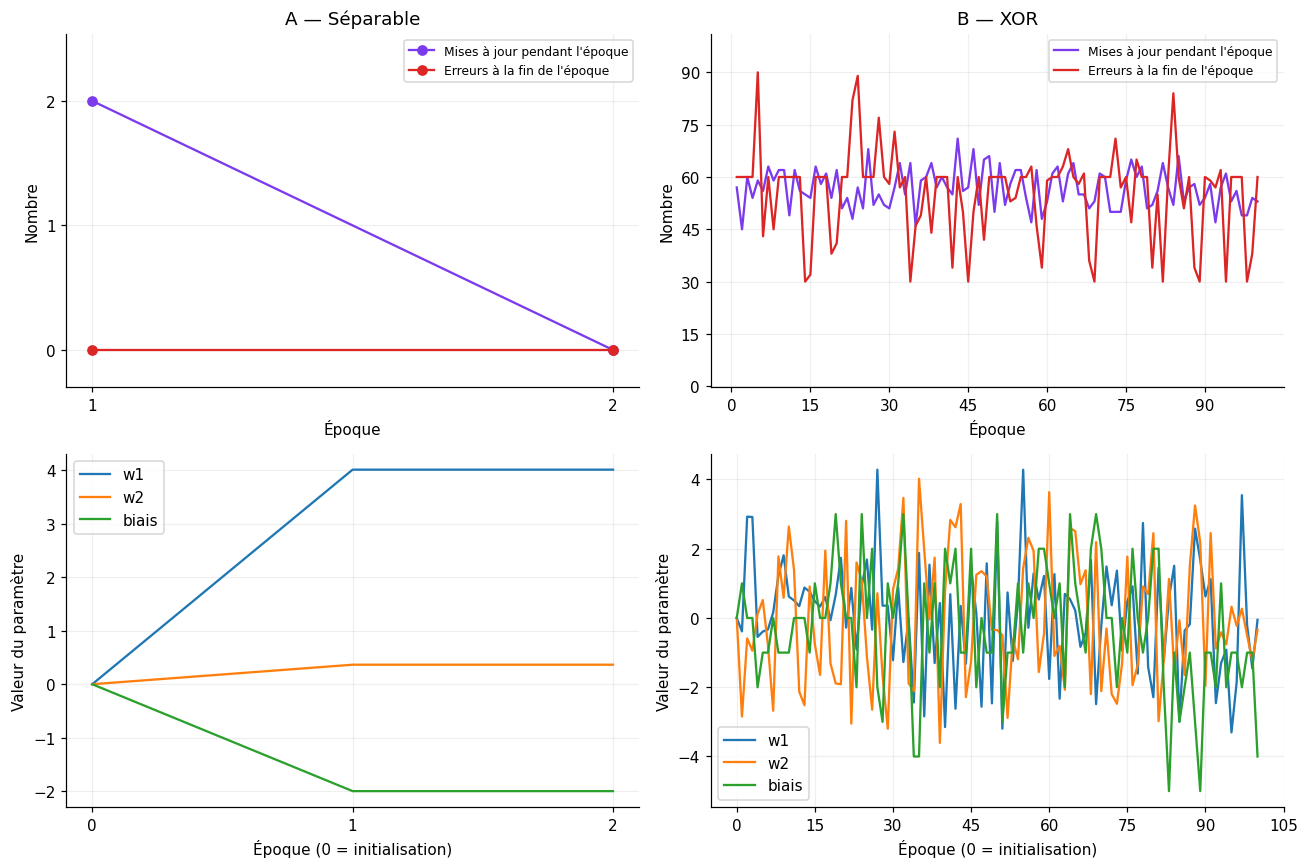

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for colonne, (nom, resultat) in enumerate([
    ("A — Séparable", resultat_sep), ("B — XOR", resultat_xor)
]):
    historique = resultat["historique"]
    epoques = np.array([h["epoque"] for h in historique])
    maj = [h["mises_a_jour"] for h in historique]
    erreurs = [h["erreurs_train"] for h in historique]

    ax = axes[0, colonne]
    marqueur = "o" if len(epoques) <= 5 else None
    ax.plot(epoques, maj, color="#7C3AED", marker=marqueur,
            label="Mises à jour pendant l'époque")
    ax.plot(epoques, erreurs, color="#DC2626", marker=marqueur,
            label="Erreurs à la fin de l'époque")
    ax.set(title=nom, xlabel="Époque", ylabel="Nombre",
           ylim=(-0.3, max(maj + erreurs + [1]) * 1.12 + 0.3))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

    ax = axes[1, colonne]
    for j, etiquette in enumerate(["w1", "w2", "biais"]):
        ax.plot(np.arange(len(resultat["poids"])), resultat["poids"][:, j],
                label=etiquette)
    ax.set(xlabel="Époque (0 = initialisation)", ylabel="Valeur du paramètre")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

**Lecture attendue :** le jeu séparable finit par avoir une époque sans correction. Les poids n'y changent plus. Sur le XOR, les erreurs fluctuent et les corrections continuent jusqu'au plafond.

La convergence théorique dépend du train. Un arrêt au plafond sur un autre jeu inconnu ne prouverait pas à lui seul la non-séparabilité ; ici, nous l'avons démontrée à partir des quatre centres.

## 11. Évaluer les modèles sur le test

Nous réutilisons les poids appris, **sans les modifier**. L'exactitude est la proportion de bonnes prédictions. Les matrices de confusion ont les **vraies classes en lignes** et les **classes prédites en colonnes**, dans l'ordre `[−1, +1]`.

Le taux sur le train décrit l'ajustement aux exemples connus ; le taux sur le test mesure les résultats sur les 30 observations mises de côté.

In [9]:
def evaluer(X, y, w):
    predictions = predire(X, w)
    erreurs = predictions != y
    confusion = np.array([
        [np.sum((y == vraie) & (predictions == predite)) for predite in [-1, 1]]
        for vraie in [-1, 1]
    ])
    return {
        "predictions": predictions,
        "erreurs": erreurs,
        "nombre_erreurs": int(np.sum(erreurs)),
        "exactitude": float(np.mean(~erreurs)),
        "confusion": confusion,
    }


evaluations = {}
for nom, resultat, yt, yte in [
    ("Séparable", resultat_sep, y_sep_train, y_sep_test),
    ("XOR", resultat_xor, y_xor_train, y_xor_test),
]:
    train = evaluer(X_train, yt, resultat["w"])
    test = evaluer(X_test, yte, resultat["w"])
    evaluations[nom] = {"train": train, "test": test}

    print(f"\n{nom}")
    print(f"  Train : {train['exactitude']:.1%}, {train['nombre_erreurs']}/120 erreurs")
    print(f"  Test  : {test['exactitude']:.1%}, {test['nombre_erreurs']}/30 erreurs")
    print("  Matrice de confusion sur le test (ordre : −1, +1) :")
    print(test["confusion"])


Séparable
  Train : 100.0%, 0/120 erreurs
  Test  : 100.0%, 0/30 erreurs
  Matrice de confusion sur le test (ordre : −1, +1) :
[[15  0]
 [ 0 15]]

XOR
  Train : 50.0%, 60/120 erreurs
  Test  : 50.0%, 15/30 erreurs
  Matrice de confusion sur le test (ordre : −1, +1) :
[[15  0]
 [15  0]]


## 12. Voir les frontières finales et les erreurs

- **Fond coloré :** classe prédite à cet endroit.
- **Couleur des points :** vraie classe.
- **Ligne noire :** score nul, lorsque cette droite traverse la zone affichée.
- **Anneau rouge :** exemple mal classé.

Chaque ligne compare le train et le test d'un même modèle. Si tout le fond a la même couleur, le modèle prédit une seule classe dans cette zone : cela peut arriver pour les derniers poids du XOR.

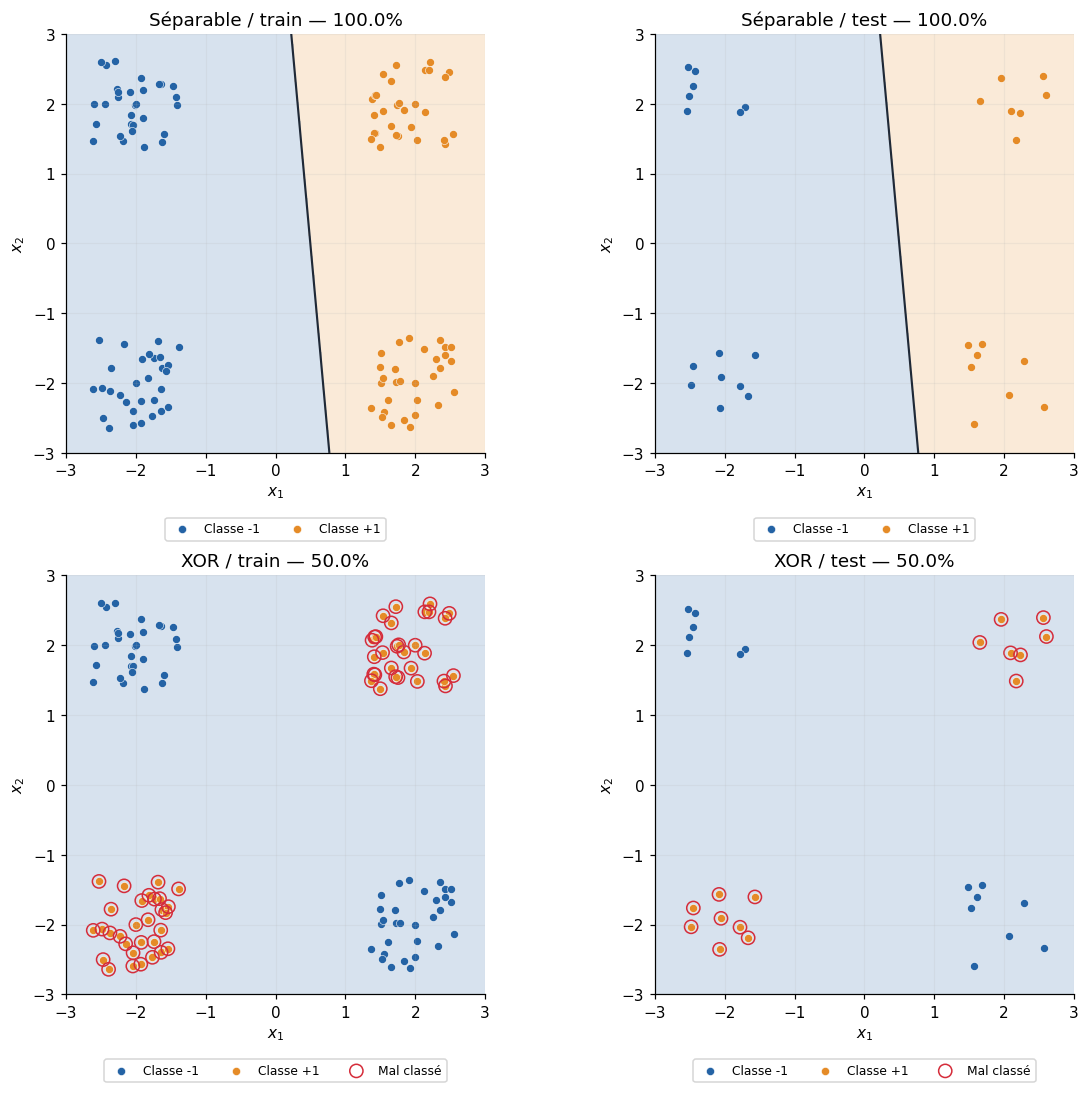

In [10]:
def afficher_modele(ax, X_points, y_points, w, titre):
    """Afficher les régions prédites et les vraies classes en deux dimensions."""
    xx, yy = np.meshgrid(
        np.linspace(*LIM, 240),
        np.linspace(*LIM, 240),
    )
    grille = np.column_stack((xx.ravel(), yy.ravel()))
    scores = (ajouter_biais(grille) @ w).reshape(xx.shape)
    regions = np.where(scores >= 0, 1, -1)

    ax.contourf(xx, yy, regions, levels=[-2, 0, 2], cmap=CMAP, alpha=0.18)
    if scores.min() < 0 < scores.max():
        ax.contour(xx, yy, scores, levels=[0], colors="#1F2937", linewidths=1.4)

    for classe in [-1, 1]:
        masque = y_points == classe
        ax.scatter(X_points[masque, 0], X_points[masque, 1],
                   color=COULEURS[classe], s=28, edgecolors="white", linewidths=0.35,
                   label=f"Classe {classe:+d}")

    erreurs = predire(X_points, w) != y_points
    if np.any(erreurs):
        ax.scatter(X_points[erreurs, 0], X_points[erreurs, 1],
                   facecolors="none", edgecolors="#D52C3A", s=75, linewidths=1.0,
                   label="Mal classé")

    exactitude = np.mean(~erreurs)
    ax.set(title=f"{titre} — {exactitude:.1%}", xlabel="$x_1$", ylabel="$x_2$",
           xlim=LIM, ylim=LIM)
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8, ncol=3)


fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ligne, (nom, resultat, yt, yte) in enumerate([
    ("Séparable", resultat_sep, y_sep_train, y_sep_test),
    ("XOR", resultat_xor, y_xor_train, y_xor_test),
]):
    afficher_modele(axes[ligne, 0], X_train, yt, resultat["w"], f"{nom} / train")
    afficher_modele(axes[ligne, 1], X_test, yte, resultat["w"], f"{nom} / test")

fig.tight_layout()
plt.show()

## 13. Observer plusieurs frontières pendant l'apprentissage du XOR

Nous affichons six états déjà enregistrés. **Aucun réentraînement n'est effectué.** Les points montrés sont ceux du train, avec les poids obtenus à chaque époque indiquée.

Observe comment une frontière peut avantager un groupe et pénaliser un autre. Une bonne époque peut être suivie d'une moins bonne : les derniers poids ne sont pas nécessairement les meilleurs rencontrés.

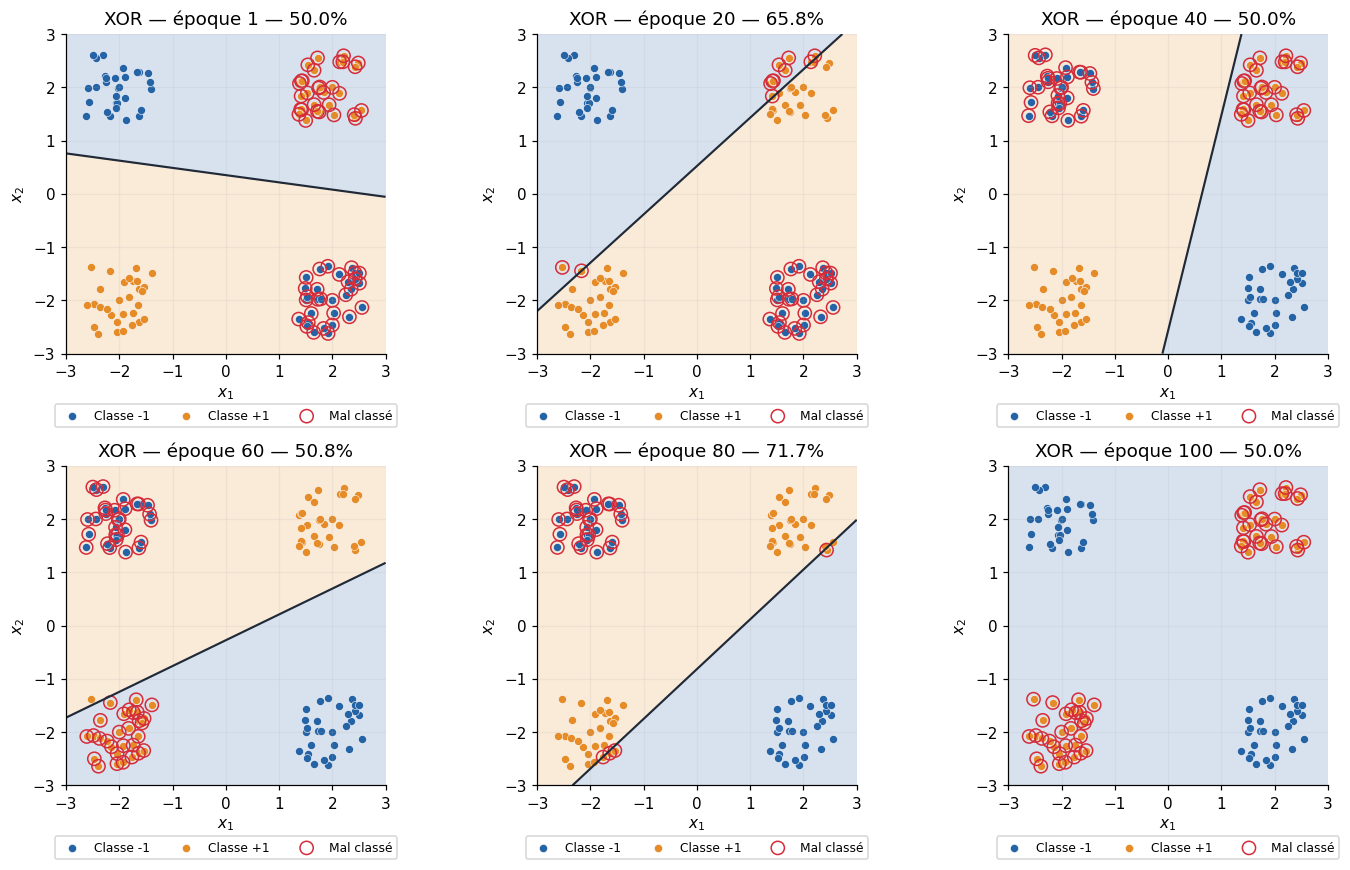

In [11]:
# Six positions réparties dans l'historique ; fonctionne aussi si le plafond change.
epoques_a_voir = np.unique(
    np.linspace(1, resultat_xor["epoques"], 6, dtype=int)
)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, epoque in zip(axes.flat, epoques_a_voir):
    afficher_modele(ax, X_train, y_xor_train,
                   resultat_xor["poids"][epoque], f"XOR — époque {epoque}")
for ax in list(axes.flat)[len(epoques_a_voir):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 14. Bonus : conserver les meilleurs poids rencontrés sur le train

L'idée du **perceptron pocket** est de garder une copie des meilleurs poids rencontrés. Nous faisons ici une version simple : nous comparons les poids **à la fin de chaque époque**, ainsi que l'initialisation. Une version plus fine pourrait aussi comparer les états intermédiaires après chaque correction.

Le critère est le nombre d'erreurs sur **le train uniquement**. En cas d'égalité, nous gardons le premier état rencontré. Cette sélection décrit l'optimisation de l'erreur d'entraînement ; elle ne garantit ni le meilleur séparateur possible, ni les meilleures performances sur le test.

Nous avons prévu cette comparaison dès la conception du notebook. On peut ensuite évaluer ce modèle fixé sur le test, mais **on ne choisit pas entre les modèles et on ne règle pas les hyperparamètres à partir de ces scores de test**. Pour cela, il faudrait un ensemble de validation ou une validation croisée.

État conservé : époque 14 (0 = initialisation)
Erreurs sur le train : 30 / 120
Exactitude sur le test : 73.3%


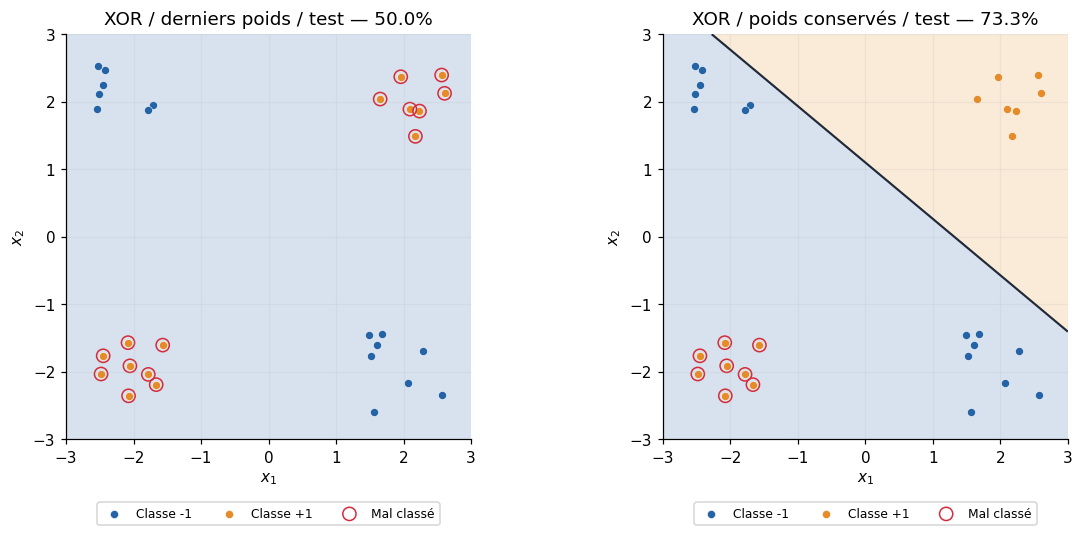

In [12]:
erreurs_par_etat = np.array([
    np.sum(predire(X_train, w) != y_xor_train)
    for w in resultat_xor["poids"]
])

meilleure_epoque = int(np.argmin(erreurs_par_etat))
w_pocket = resultat_xor["poids"][meilleure_epoque].copy()

print("État conservé : époque", meilleure_epoque, "(0 = initialisation)")
print("Erreurs sur le train :", erreurs_par_etat[meilleure_epoque], "/ 120")

evaluation_pocket = evaluer(X_test, y_xor_test, w_pocket)
print(f"Exactitude sur le test : {evaluation_pocket['exactitude']:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
afficher_modele(axes[0], X_test, y_xor_test, resultat_xor["w"], "XOR / derniers poids / test")
afficher_modele(axes[1], X_test, y_xor_test, w_pocket, "XOR / poids conservés / test")
fig.tight_layout()
plt.show()

## 15. Lien avec la fonction de perte

La perte du perceptron pour un exemple est :

$$\ell_i(w)=\max(0,-y_iw^\top\widetilde x_i).$$

Lorsque la marge est négative, son gradient est $-y_i\widetilde x_i$ : le pas $w\leftarrow w-\eta\nabla\ell_i$ donne exactement la mise à jour programmée. À marge nulle, nous choisissons le sous-gradient $-y_i\widetilde x_i$ pour effectuer une correction.

**Attention au piège du coût nul :** à l'initialisation $w=0$, cette perte vaut zéro pour tous les exemples, mais tous les scores sont aussi nuls. Cela ne constitue pas un bon classifieur. Notre condition d'arrêt se fonde sur une époque sans mise à jour, ce qui exige ici des marges strictement positives sur le train, et non simplement sur une perte nulle.

## 16. Ce qu'il faut retenir

| Observation | Ce qu'elle permet de conclure |
|---|---|
| Une époque avec 0 mise à jour | Le train est bien classé avec des marges strictement positives ; les poids n'ont pas changé pendant le passage |
| Un nombre de mises à jour constant mais positif | Cela ne prouve pas la convergence des poids |
| Le plafond d'époques est atteint | On a arrêté l'algorithme ; on n'a pas démontré sa convergence |
| Les erreurs augmentent après une correction | C'est possible : la frontière affecte toutes les observations |
| 0 erreur sur le train | Cela ne garantit pas 0 erreur sur de nouvelles données |
| Le XOR reste imparfait | La famille de frontières linéaires est insuffisante pour ce jeu |

Sur un jeu non séparable, un meilleur réglage peut améliorer le résultat, mais ne peut pas rendre parfaite une séparation linéaire impossible. Des caractéristiques supplémentaires, par exemple le produit `x1*x2` pour ce XOR, ou un modèle non linéaire changeraient la famille de frontières disponibles.

## 17. Petits exercices pour vérifier ta compréhension

1. Pourquoi avons-nous 3 paramètres alors que les observations ont 2 caractéristiques ?
2. Pourquoi une époque avec 120 observations peut-elle ne contenir que 2 mises à jour ?
3. Pourquoi ne compare-t-on pas directement les scores numériques aux cibles −1 et +1 ?
4. Pourquoi une époque avec 4 mises à jour n'indique-t-elle pas forcément 4 erreurs du modèle final ?
5. Change `SEED_ORDRE` et relance l'entraînement. Une autre frontière sur le jeu séparable peut-elle être également correcte ?
6. Passe `melanger=False`. Pourquoi cela peut-il changer le parcours des poids sans rendre le XOR séparable ?
7. Sur le XOR, doubler le plafond d'époques garantit-il une amélioration ? Explique avec les courbes du train.
8. Quelle différence y a-t-il entre limiter la durée de l'entraînement, choisir ses meilleurs poids d'entraînement et choisir un hyperparamètre avec une validation ?

Pour les expériences 5 à 7, compare les courbes d'entraînement. Si tu utilises les résultats du test pour décider quoi modifier, il ne constitue plus une évaluation finale indépendante.